# 06. User characteristics

**Goal**: 04 and 05 asked in which **situations** notifications work. 06 asks for which **people**. Check how much engagement and the step effect differ between participants, and whether the differences relate to user characteristics (age, gender, usual activity, self-efficacy, prior use of fitness apps or trackers).

**Caution**: There are thousands of decision points, but each person has only one value of each characteristic. Comparisons by characteristic are effectively **comparisons among 37 people**, with even less power than the situation comparisons in 04. Results are treated as hypotheses.

**Questions**
1. How much do engagement and the effect differ between participants? Do people who respond more gain more?
2. Which people respond more?
3. For which people is the step effect larger?
4. Do engagement and the effect diverge across characteristics too?

## 0. Setup

In [3]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf

pd.set_option("display.max_columns", None)

# This notebook lives in notebooks/, so the project folder is one level up.
PROJECT_DIR = Path("..")
RAW_DIR = PROJECT_DIR / "data" / "raw"
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"

BLUE = "#2a78d6"
GREY = "#9a9893"
plt.rcParams.update({
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e6e5e0",
    "axes.axisbelow": True,
})

decision_points = pd.read_csv(PROCESSED_DIR / "decision_points.csv")
users = pd.read_csv(RAW_DIR / "users.csv")
print(decision_points.shape, users.shape)

(8274, 31) (37, 117)


### 0.1. Functions
Same as in 04.

In [ ]:
OUTCOME = "log_steps_post30_zero"
PRE = "log_steps_pre30_zero"


def fit_gee(formula, data):
    model = smf.gee(
        formula,
        groups="user_id",                         # standard errors per participant
        data=data,
        cov_struct=sm.cov_struct.Independence(),
        missing="drop",                           # skip rows with a missing value in the formula
    )
    result = model.fit(cov_type="bias_reduced")   # small-sample correction
    ci = result.conf_int()
    table = pd.DataFrame({
        "estimate": result.params,
        "std_err": result.bse,
        "p_value": result.pvalues,
        "ci_low": ci[0],
        "ci_high": ci[1],
    })
    return table.round(3)


def effect_by_group(data, context, treatment, outcome=OUTCOME, pre=PRE):
    rows = []
    for group, subset in data.groupby(context):           # rows with a missing context are skipped
        table = fit_gee(f"{outcome} ~ {pre} + {treatment}", subset)
        rows.append({
            "context": context,
            "group": group,
            "n_rows": len(subset),
            "participants": subset["user_id"].nunique(),
            "estimate": table.loc[treatment, "estimate"],
            "p_value": table.loc[treatment, "p_value"],
            "ci_low": table.loc[treatment, "ci_low"],
            "ci_high": table.loc[treatment, "ci_high"],
        })
    result = pd.DataFrame(rows)
    for col in ["estimate", "ci_low", "ci_high"]:
        result[f"{col}_pct"] = ((np.exp(result[col]) - 1) * 100).round(1)
    return result

# 그룹 사이 차이 효과 검증
def difference_p(data, context, treatment, outcome=OUTCOME, pre=PRE):
    formula = f"{outcome} ~ {pre} + C({context}) + {treatment} + {treatment}:C({context})"
    model = smf.gee(formula, groups="user_id", data=data,
                    cov_struct=sm.cov_struct.Independence(), missing="drop")
    result = model.fit(cov_type="bias_reduced")
    tests = result.wald_test_terms(skip_single=False, scalar=True).table
    return tests.loc[f"{treatment}:C({context})", "pvalue"]

---

## 1. User characteristics

From the intake survey, pick 5 characteristics likely to relate to engagement or steps. All are known **before** using the app, so a real service could collect them at sign-up and use them to set up notifications.

| Characteristic | Raw column | Groups |
| --- | --- | --- |
| Gender | `gender` | female, male |
| Age | `age` | at or below the median vs above |
| Usual activity | `metmins.intake` (MET-minutes per week) | lower, higher (by median) |
| Exercise self-efficacy | `selfeff.intake` | lower, higher (by median) |
| Prior fitness app or tracker | `fitapp`, `fittracker` |  yes to either -> used before; no to both -> new |

Continuous characteristics are split into two groups at the median; finer groups would leave too few people each. Values equal to the median go to the lower group.

### 1-1. Distributions of the numeric characteristics

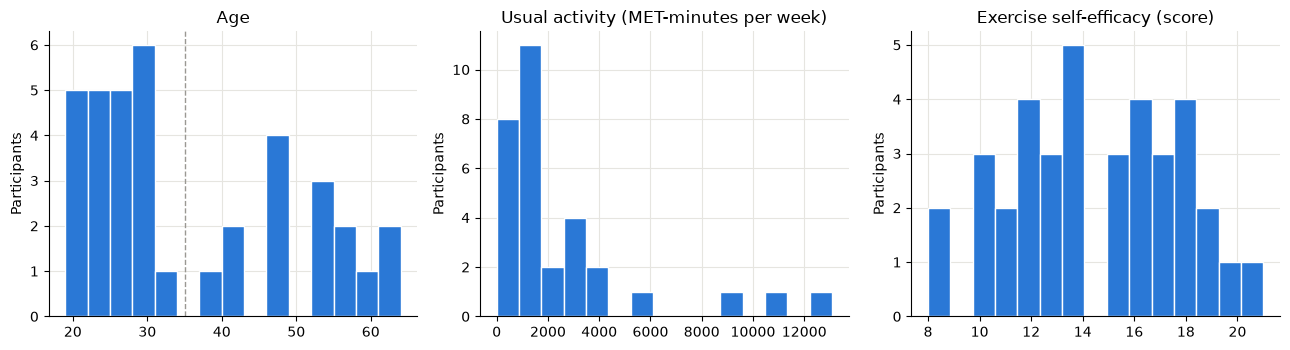

Ages in order: [19, 20, 20, 20, 21, 22, 22, 23, 24, 24, 25, 25, 26, 26, 27, 28, 28, 28, 28, 29, 30, 33, 39, 41, 41, 46, 46, 47, 48, 52, 53, 54, 55, 57, 60, 63, 64]
Missing usual activity (metmins.intake): 6 participants


In [5]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, col, title in zip(
    axes,
    ["age", "metmins.intake", "selfeff.intake"],
    ["Age", "Usual activity (MET-minutes per week)", "Exercise self-efficacy (score)"],
):
    ax.hist(users[col].dropna(), bins=15, color=BLUE, edgecolor="white")
    ax.set(title=title, ylabel="Participants")
axes[0].axvline(35, color=GREY, linestyle="--", linewidth=1)   # the age split used below
plt.tight_layout()
plt.show()

print(f"Ages in order: {sorted(users['age'].tolist())}")
print(f"Missing usual activity (metmins.intake): {users['metmins.intake'].isna().sum()} participants")

- **Age** forms two clusters: 21 people aged 19-30 and 15 aged 39-64, with only one person (33) in between. Splitting at the median (28) would cut through the younger cluster, so the split is at **35**, in the empty range.
- **Usual activity** is strongly right-skewed by a few very active people, and 6 people did not answer. The raw data also has the IPAQ **activity level** (`ipaq.hepa.intake`) from the same survey, with no one missing, so that is used instead.
- **Self-efficacy** is spread evenly in one cluster, so it is split at the median.

To check what the activity levels (1, 2, 3) mean, look at median MET-minutes per week for each level.

In [6]:
users.groupby("ipaq.hepa.intake").agg(
    participants=("user.index", "size"),
    median_metmins=("metmins.intake", "median"),
)

,participants,median_metmins
ipaq.hepa.intake,,
1,11,442.75
2,15,1409.10
3,11,4065.75


- Activity rises from 1 to 3, matching the standard IPAQ levels (low, moderate, high).

### 1-2. Building the groups

| Characteristic | Groups | Rule |
| --- | --- | --- |
| Gender | female, male | as is |
| Age | under 35, 35 and over | the gap in the distribution |
| Usual activity | low, moderate, high | IPAQ levels 1, 2, 3 |
| Self-efficacy | lower, higher | at or below vs above the median |
| Prior fitness app or tracker | new, used before | yes to either → used before |

In [7]:
traits = users[["user.index", "gender", "age", "ipaq.hepa.intake", "selfeff.intake", "fitapp", "fittracker"]].rename(
    columns={"user.index": "user_id"}
)
traits["age_group"] = np.where(traits["age"] >= 35, "35 and over", "under 35")
traits["activity_level"] = traits["ipaq.hepa.intake"].map({1: "low", 2: "moderate", 3: "high"})
traits["selfeff_group"] = np.where(traits["selfeff.intake"] > traits["selfeff.intake"].median(), "higher", "lower")
traits["fitness_tech"] = np.where((traits["fitapp"] == "yes") | (traits["fittracker"] == "yes"), "used before", "new")

TRAITS = ["gender", "age_group", "activity_level", "selfeff_group", "fitness_tech"]

print(f"Self-efficacy median: {traits['selfeff.intake'].median()}")
print()
for trait in TRAITS:
    print(traits[trait].value_counts())
    print()

Self-efficacy median: 14.0

gender
female    24
male      13
Name: count, dtype: int64

age_group
under 35       22
35 and over    15
Name: count, dtype: int64

activity_level
moderate    15
high        11
low         11
Name: count, dtype: int64

selfeff_group
lower     19
higher    18
Name: count, dtype: int64

fitness_tech
new            23
used before    14
Name: count, dtype: int64



- Each group has 11-24 people, with no one missing.
- There are more women (24) than men (13); 14 people have used a fitness app or tracker.

### 1-3. Who the participants are

Beyond the characteristics in 1.2, look at occupation, education, marital status, children, and ethnicity to describe who the participants are. These are not tested for effects; only their overlap with the age groups is checked, because comparing many characteristics among 37 people makes chance differences more likely.

- `student`: "student" appears in the free-text occupation
- `married`: married or in a domestic partnership
- `has_children`: one or more children

In [8]:
profile = users[["user.index", "occupation", "education", "marital", "children", "ethnicity"]].rename(
    columns={"user.index": "user_id"}
)
profile["student"] = np.where(profile["occupation"].str.contains("student", case=False, na=False), "student", "not student")
profile["married"] = np.where(profile["marital"].isin(["married", "domestic partnership"]), "yes", "no")
profile["has_children"] = np.where(profile["children"] > 0, "yes", "no")
profile = profile.merge(traits[["user_id", "age_group"]], on="user_id")

print("Occupations of non-students:")
print(profile.loc[profile["student"] == "not student", "occupation"].tolist())
print()
for col in ["student", "education", "married", "has_children", "ethnicity"]:
    print(profile[col].value_counts())
    print()

Occupations of non-students:
['program coordinator', 'engineering intern, lifegaurd', 'engineer', 'statistician', 'research intern', 'clerk, deputy', 'IT manager', 'immigration officer', 'senior administrative assistant', 'healthcare researcher', 'psychologist', 'research INP', 'environmental health specialist', 'administrative assistant', 'professor', 'preschool teacher', 'preschool teacher, school age child care, photographer', 'customer service (Comcast)', 'social worker', 'engineer']

student
not student    20
student        17
Name: count, dtype: int64

education
grad degree         14
college grad        12
some college         6
some grad school     5
Name: count, dtype: int64

married
no     25
yes    12
Name: count, dtype: int64

has_children
no     24
yes    13
Name: count, dtype: int64

ethnicity
white/caucasian           22
asian/pacific islander    10
black/african american     2
american indian            1
hispanic/latino            1
other                      1
Name: c

- Check how much student status, marriage, and children overlap with the age groups (split at 35).

In [9]:
for col in ["student", "married", "has_children"]:
    print(pd.crosstab(profile[col], profile["age_group"]))
    print()

age_group    35 and over  under 35
student                           
not student           15         5
student                0        17

age_group  35 and over  under 35
married                         
no                   4        21
yes                 11         1

age_group     35 and over  under 35
has_children                       
no                      2        22
yes                    13         0



- All 17 students are under 35, and all 13 parents are 35 or over; 11 of the 12 married participants are 35 or over.
- The participants form two groups: **students in their 20s** (single, no children) and **working adults and parents aged 40 and over**. This is why age formed two clusters in section 1.1.
- Occupation, marriage, and children split people almost the same way as age, so they are not analyzed separately. **The age group stands for this life stage.**
- This is a highly educated, university-centered group (17 students, 14 with graduate degrees), so the results may not carry over directly to general app users (see limitations in section 6).

### 1-4. Analysis samples
Attach the characteristics to the decision points and build the same two samples as in 05.

In [10]:
sample = decision_points[(decision_points["available"] == 1) & (decision_points["travel_day"] == 0)]
sample = sample.merge(traits[["user_id"] + TRAITS], on="user_id", how="left")
sample["active"] = (sample["send_type"] == "active").astype(int)

walk_vs_none = sample[sample["send_type"].isin(["active", "none"])]
engage_walk = sample[(sample["send_type"] == "active") & sample["engaged"].notna()]

print(f"Sample: {len(sample)} rows, {sample['user_id'].nunique()} participants")
print(f"Walking vs none: {len(walk_vs_none)} rows")
print(f"Walking notifications with a response record: {len(engage_walk)}")

Sample: 6331 rows, 37 participants
Walking vs none: 4675 rows
Walking notifications with a response record: 1616


---

## 2. Engagement and effect per participant

For each participant, compute the engagement rate and the step effect of walking notifications. The effect comes from fitting `outcome ~ steps before + walking notification` on that person's data alone. It is a comparison within one person, so no clustering is needed and ordinary regression (`smf.ols`) is used.

**Caution**: Each person has about 57 walking notifications, so individual effects are uncertain; part of the spread between people comes from this.

In [11]:
rows = []
for user_id, person in walk_vs_none.groupby("user_id"):
    model = smf.ols(f"{OUTCOME} ~ {PRE} + active", person).fit()
    rows.append({
        "user_id": user_id,
        "walking_sent": person["active"].sum(),
        "effect_pct": (np.exp(model.params["active"]) - 1) * 100,
    })

per_user = pd.DataFrame(rows).set_index("user_id")
per_user["engagement_rate"] = engage_walk.groupby("user_id")["engaged"].mean()
per_user = per_user.round(3)

per_user[["walking_sent", "engagement_rate", "effect_pct"]].describe().round(2)

,walking_sent,engagement_rate,effect_pct
count,37.00,37.00,37.00
mean,56.73,0.68,38.30
std,9.63,0.20,67.84
min,31.00,0.23,-57.30
25%,50.00,0.53,-17.86
50%,56.00,0.72,25.06
75%,63.00,0.83,70.74
max,76.00,1.00,199.77


Participants with a positive effect: 24 of 37
Rank correlation between engagement and effect: 0.20


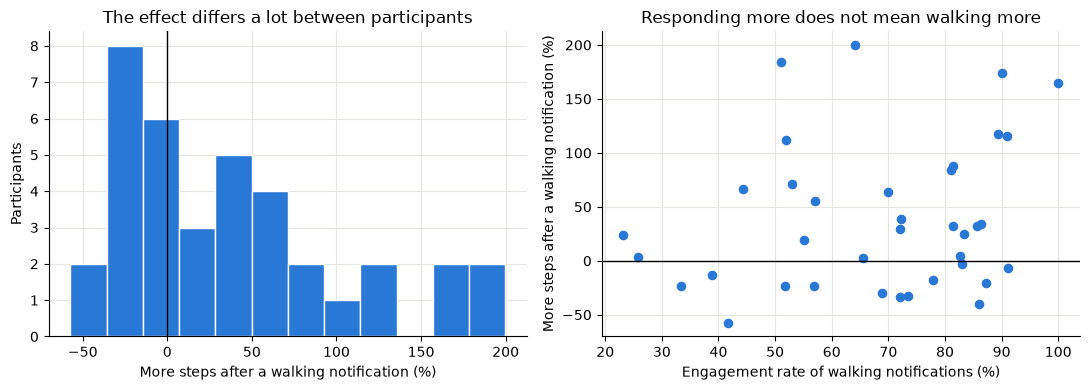

In [12]:
print(f"Participants with a positive effect: {(per_user['effect_pct'] > 0).sum()} of {len(per_user)}")
print(f"Rank correlation between engagement and effect: {per_user['engagement_rate'].corr(per_user['effect_pct'], method='spearman'):.2f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].hist(per_user["effect_pct"], bins=12, color=BLUE, edgecolor="white")
axes[0].axvline(0, color="black", linewidth=1)
axes[0].set(title="The effect differs a lot between participants",
            xlabel="More steps after a walking notification (%)", ylabel="Participants")

axes[1].scatter(per_user["engagement_rate"] * 100, per_user["effect_pct"], color=BLUE, s=35)
axes[1].axhline(0, color="black", linewidth=1)
axes[1].set(title="Responding more does not mean walking more",
            xlabel="Engagement rate of walking notifications (%)",
            ylabel="More steps after a walking notification (%)")

plt.tight_layout()
plt.show()

- Individual effects range from -57% to +200%; 24 of 37 are positive and 13 are zero or below. Notifications do not work the same for everyone.
- The rank correlation between engagement and the effect is weak (0.20). **People who respond more are not the ones who gain more.** The "engagement is not the effect" finding of 05 appears at the person level too.

---

## 3. Engagement by characteristic
Average the participants' engagement rates (section 2) within each group. Averaging **per person** rather than per notification keeps people with more notifications from dominating (one vote per person).

In [13]:
per_user = per_user.join(traits.set_index("user_id")[TRAITS])

for trait in TRAITS:
    print(per_user.groupby(trait).agg(
        engagement_rate=("engagement_rate", "mean"),
        participants=("engagement_rate", "size"),
    ).round(3))
    print()

        engagement_rate  participants
gender                               
female            0.650            24
male              0.737            13

             engagement_rate  participants
age_group                                 
35 and over            0.614            15
under 35               0.727            22

                engagement_rate  participants
activity_level                               
high                      0.743            11
low                       0.639            11
moderate                  0.666            15

               engagement_rate  participants
selfeff_group                               
higher                   0.668            18
lower                    0.694            19

              engagement_rate  participants
fitness_tech                               
new                     0.715            23
used before             0.625            14



- Men (73.7%) respond more than women (65.0%), people under 35 (72.7%) more than those 35 and over (61.4%), highly active people (74.3%) more than those with low activity (63.9%), and newcomers to fitness apps or trackers (71.5%) more than prior users (62.5%).
- Self-efficacy shows a small difference (69.4% vs 66.8%).

---

## 4. Step effect by characteristic
As in 04, estimate the effect of walking notifications within each group (`effect_by_group`) and test the difference between groups (`difference_p`).

In [14]:
trait_effects = pd.concat(
    [effect_by_group(walk_vs_none, trait, "active") for trait in TRAITS],
    ignore_index=True,
)
trait_effects["difference_p"] = trait_effects["context"].map(
    {trait: round(difference_p(walk_vs_none, trait, "active"), 3) for trait in TRAITS}
)
trait_effects[["context", "group", "participants", "estimate_pct", "ci_low_pct", "ci_high_pct", "p_value", "difference_p"]]

,context,group,participants,estimate_pct,ci_low_pct,ci_high_pct,p_value,difference_p
0,gender,female,24,22.5,2.0,47.0,0.029,0.856
1,gender,male,13,27.1,-9.2,77.9,0.162,0.856
2,age_group,35 and over,15,23.1,-3.5,57.0,0.095,0.943
3,age_group,under 35,22,24.4,-1.5,57.0,0.066,0.943
4,activity_level,high,11,29.7,-9.3,85.5,0.155,0.491
5,activity_level,low,11,9.0,-14.7,39.2,0.492,0.491
6,activity_level,moderate,15,34.2,0.7,79.0,0.045,0.491
7,selfeff_group,higher,18,19.0,-5.2,49.3,0.133,0.670
8,selfeff_group,lower,19,27.8,0.5,62.4,0.046,0.670
9,fitness_tech,new,23,39.0,14.5,68.5,0.001,0.087


- **Prior fitness app or tracker use** shows the largest difference: +39.0% (p = 0.001) for newcomers vs +2.9% (p = 0.840) for those who used one before. The difference test is borderline (p = 0.087).
- People with low activity show a small effect (+9.0% vs +34.2% moderate and +29.7% high), but the difference is not confirmed (p = 0.491).
- Gender, age, and self-efficacy show small differences in effect, all with p > 0.6; for age, the effects are almost identical (+24.4% vs +23.1%).
- Interpretation: walking notifications may not feel new to people who have used similar apps, so they respond less to them. This fits the "novelty effect" seen in 03, where the effect was large only early on. With only 14 people, it remains a hypothesis.

### 4-1. Sensitivity analysis
Recompute with missing steps left out and compare the effects (%).

In [15]:
trait_effects_left_out = pd.concat(
    [effect_by_group(walk_vs_none, trait, "active", outcome="log_steps_post30", pre="log_steps_pre30")
     for trait in TRAITS],
    ignore_index=True,
)

trait_effects[["context", "group", "estimate_pct", "p_value"]].merge(
    trait_effects_left_out[["context", "group", "estimate_pct", "p_value"]],
    on=["context", "group"],
    suffixes=("_missing_0", "_left_out"),
)

,context,group,estimate_pct_missing_0,p_value_missing_0,estimate_pct_left_out,p_value_left_out
0,gender,female,22.5,0.029,23.0,0.031
1,gender,male,27.1,0.162,22.6,0.265
2,age_group,35 and over,23.1,0.095,27.3,0.060
3,age_group,under 35,24.4,0.066,20.3,0.142
4,activity_level,high,29.7,0.155,25.6,0.233
5,activity_level,low,9.0,0.492,7.9,0.488
6,activity_level,moderate,34.2,0.045,34.3,0.071
7,selfeff_group,higher,19.0,0.133,19.6,0.140
8,selfeff_group,lower,27.8,0.046,25.5,0.086
9,fitness_tech,new,39.0,0.001,33.9,0.005


- The difference by prior fitness app or tracker use holds with missing values left out (newcomers +33.9%, prior users +7.1%), as does the small effect for low activity (+7.9%). The other characteristics show small differences in both versions.

---

## 5. Engagement compared with the effect

Put the engagement rates (section 3) and effects (section 4) side by side for each group.

In [16]:
rows = []
for trait in TRAITS:
    rate = per_user.groupby(trait)["engagement_rate"].mean()
    for group, value in rate.items():
        rows.append({"context": trait, "group": group, "engagement_rate": round(value, 3)})

trait_compare = pd.DataFrame(rows).merge(
    trait_effects[["context", "group", "estimate_pct", "p_value"]], on=["context", "group"]
)
trait_compare

,context,group,engagement_rate,estimate_pct,p_value
0,gender,female,0.650,22.5,0.029
1,gender,male,0.737,27.1,0.162
2,age_group,35 and over,0.614,23.1,0.095
3,age_group,under 35,0.727,24.4,0.066
4,activity_level,high,0.743,29.7,0.155
5,activity_level,low,0.639,9.0,0.492
6,activity_level,moderate,0.666,34.2,0.045
7,selfeff_group,higher,0.667,19.0,0.133
8,selfeff_group,lower,0.694,27.8,0.046
9,fitness_tech,new,0.715,39.0,0.001


- **Age**: people 35 and over respond much less (61.4% vs 72.7%) but gain the same (+23.1% vs +24.4%).
- **Gender**: men respond more (73.7% vs 65.0%) but gain about the same (+27.1% vs +22.5%).
- **Activity level**: highly active people respond the most (74.3%) but do not gain more than moderately active people (+29.7% vs +34.2%). People with low activity are low on both engagement (63.9%) and effect (+9.0%).
- **Prior fitness app or tracker use**: prior users respond less (62.5%) and gain almost nothing (+2.9%); here both measures point the same way.
- -> Across characteristics too, the group that responds more is not the one that gains more, although most differences in effect were not statistically confirmed (section 4).


## 6. Summary

| Question |  Answer |
| --- | --- |
| Does the effect differ by person? | Yes: -57% to +200%, positive for 24 of 37 |
| Do heavy responders gain more? | No: rank correlation 0.20 |
| Who responds more? | Men, people under 35, highly active people, newcomers to fitness apps or trackers |
| Who gains more? | Newcomers to fitness apps or trackers (+39.0% vs +2.9%, difference p = 0.087) |

**Candidates for 07**
- Walking notifications barely work for people who have used fitness apps or trackers; reducing them or trying different content (e.g. goal setting, progress feedback) is a candidate to test.
- A single sign-up question ("Have you used a fitness app or tracker?") is enough to split users, so the cost of applying it is low.

**Limitations**
- Comparisons by characteristic involve only 37 people and have very little power; even the fitness-app difference is borderline (p = 0.087).
- With 5 characteristics compared, one may look different by chance.
- Turning numeric characteristics into groups loses information. The age cut (35) was chosen from the gap in the age distribution, not from the step results.
- The characteristics are self-reported at intake.

**Next**: 07 combines 03 (time), 04 (situation), 05 (engagement is not the effect), and 06 (users) into notification policy proposals.